In [23]:
# ==========================================
# MODULE 1: IMPORTING REQUIRED LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

In [4]:
# ==========================================
# MODULE 2: LOADING THE DATASET
# ==========================================

df = pd.read_csv("student_records.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

Dataset loaded successfully!
Number of rows and columns: (10000, 14)


In [5]:
# Display first 5 records
df.head()

,StudentID,Name,Age,Gender,Class,Math,Science,English,History,Computer,AttendancePercent,Extracurricular,Total,Grade
0,S10000,Brianna Smith,16,Female,12,47,85,67,68,81,61.70,NaN,348,C
1,S10001,Rebecca Vargas,15,Male,8,40,94,42,66,70,69.78,Drama,312,C
2,S10002,Christopher Taylor,17,Male,7,71,59,30,88,94,71.95,Music,342,C
3,S10003,Jared Riley,11,Female,7,72,78,32,38,92,81.31,Football,312,C
4,S10004,Kevin Huff,14,Female,11,87,79,84,53,77,81.37,NaN,380,C


In [6]:
# Display last 5 records
df.tail()
# Display all column names
print(df.columns.tolist())
# Number of rows and columns
rows, columns = df.shape

print("Total Students:", rows)
print("Total Features:", columns)
df.info()
df.describe()
df.isnull().sum()
print("Duplicate records:", df.duplicated().sum())

['StudentID', 'Name', 'Age', 'Gender', 'Class', 'Math', 'Science', 'English', 'History', 'Computer', 'AttendancePercent', 'Extracurricular', 'Total', 'Grade']
Total Students: 10000
Total Features: 14
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          10000 non-null  object 
 1   Name               10000 non-null  object 
 2   Age                10000 non-null  int64  
 3   Gender             10000 non-null  object 
 4   Class              10000 non-null  int64  
 5   Math               10000 non-null  int64  
 6   Science            10000 non-null  int64  
 7   English            10000 non-null  int64  
 8   History            10000 non-null  int64  
 9   Computer           10000 non-null  int64  
 10  AttendancePercent  10000 non-null  float64
 11  Extracurricular    8348 non-null   object 
 12  Total          

In [7]:
# ==========================================
# MODULE 3: DATA CLEANING
# ==========================================

clean_df = df.copy()

print("Backup dataset created.")
print("Missing values before cleaning:")
print(clean_df.isnull().sum())

Backup dataset created.
Missing values before cleaning:
StudentID               0
Name                    0
Age                     0
Gender                  0
Class                   0
Math                    0
Science                 0
English                 0
History                 0
Computer                0
AttendancePercent       0
Extracurricular      1652
Total                   0
Grade                   0
dtype: int64


In [8]:
print("Missing values before cleaning:")
print(clean_df.isnull().sum())
clean_df["Extracurricular"] = (
    clean_df["Extracurricular"]
    .fillna("Not Specified")
)

print("Missing extracurricular values handled.")
text_columns = clean_df.select_dtypes(
    include="object"
).columns

for col in text_columns:
    clean_df[col] = clean_df[col].astype(str).str.strip()

print("Text columns cleaned.")

Missing values before cleaning:
StudentID               0
Name                    0
Age                     0
Gender                  0
Class                   0
Math                    0
Science                 0
English                 0
History                 0
Computer                0
AttendancePercent       0
Extracurricular      1652
Total                   0
Grade                   0
dtype: int64
Missing extracurricular values handled.
Text columns cleaned.


In [9]:
numeric_columns = [
    "Age",
    "Class",
    "Math",
    "Science",
    "English",
    "History",
    "Computer",
    "AttendancePercent",
    "Total"
]

for col in numeric_columns:
    clean_df[col] = pd.to_numeric(
        clean_df[col],
        errors="coerce"
    )

print("Numerical columns converted.")

Numerical columns converted.


In [10]:
subject_columns = [
    "Math",
    "Science",
    "English",
    "History",
    "Computer"
]

for col in subject_columns:
    clean_df = clean_df[
        clean_df[col].between(0, 100)
    ]

clean_df = clean_df[
    clean_df["AttendancePercent"].between(0, 100)
]

print("Marks and attendance validated.")

Marks and attendance validated.


In [11]:
clean_df["CalculatedTotal"] = clean_df[
    subject_columns
].sum(axis=1)

clean_df["Average"] = clean_df[
    subject_columns
].mean(axis=1)

print(clean_df[
    ["StudentID", "CalculatedTotal", "Average"]
].head())

  StudentID  CalculatedTotal  Average
0    S10000              348     69.6
1    S10001              312     62.4
2    S10002              342     68.4
3    S10003              312     62.4
4    S10004              380     76.0


In [12]:
# ==========================================
# MODULE 4: NUMPY STATISTICAL ANALYSIS
# ==========================================

marks_array = clean_df[
    subject_columns
].to_numpy(dtype=float)

print("NumPy array shape:", marks_array.shape)
overall_mean = np.mean(marks_array)
overall_median = np.median(marks_array)
overall_std = np.std(marks_array)
highest_mark = np.max(marks_array)
lowest_mark = np.min(marks_array)

print("Overall Mean:", round(overall_mean, 2))
print("Overall Median:", round(overall_median, 2))
print("Standard Deviation:", round(overall_std, 2))
print("Highest Mark:", highest_mark)
print("Lowest Mark:", lowest_mark)
for i, subject in enumerate(subject_columns):
    average = np.mean(marks_array[:, i])
    print(f"{subject} Average: {average:.2f}")

NumPy array shape: (10000, 5)
Overall Mean: 64.38
Overall Median: 64.0
Standard Deviation: 20.17
Highest Mark: 99.0
Lowest Mark: 30.0
Math Average: 64.04
Science Average: 64.57
English Average: 64.53
History Average: 64.33
Computer Average: 64.44


In [13]:
# ==========================================
# MODULE 5: PANDAS DATA ANALYSIS
# ==========================================

subject_summary = pd.DataFrame({
    "Average": clean_df[subject_columns].mean(),
    "Median": clean_df[subject_columns].median(),
    "Maximum": clean_df[subject_columns].max(),
    "Minimum": clean_df[subject_columns].min(),
    "Standard Deviation": clean_df[subject_columns].std()
}).round(2)

subject_summary

,Average,Median,Maximum,Minimum,Standard Deviation
Math,64.04,64.0,99,30,20.19
Science,64.57,65.0,99,30,20.11
English,64.53,64.0,99,30,20.14
History,64.33,64.0,99,30,20.20
Computer,64.44,64.0,99,30,20.22


In [14]:
strongest_subject = subject_summary["Average"].idxmax()
weakest_subject = subject_summary["Average"].idxmin()

print("Highest average subject:", strongest_subject)
print("Lowest average subject:", weakest_subject)
top_students = clean_df.sort_values(
    by=["Average", "AttendancePercent"],
    ascending=[False, False]
).head(10)

top_students[
    [
        "StudentID",
        "Name",
        "Average",
        "AttendancePercent"
    ]
]
support_students = clean_df[
    (clean_df["Average"] < 50) |
    (clean_df["AttendancePercent"] < 75)
].sort_values(by="Average")

support_students[
    [
        "StudentID",
        "Name",
        "Average",
        "AttendancePercent"
    ]
].head(20)

Highest average subject: Science
Lowest average subject: Math


,StudentID,Name,Average,AttendancePercent
8673,S18673,Kathy Lee,35.4,92.50
9356,S19356,Michael Reyes,35.6,99.06
6294,S16294,Melissa Beck,36.4,62.43
885,S10885,John Tucker,36.8,67.22
6957,S16957,Ronald Silva,37.2,60.77
3036,S13036,Debbie Molina,37.8,73.49
3970,S13970,Natasha Rosario,38.0,72.38
126,S10126,Sarah Richardson,38.0,77.40
7323,S17323,Tonya Smith,38.6,75.42
4526,S14526,Matthew Smith,38.6,78.84


In [15]:
# ==========================================
# MODULE 6: GRADE CLASSIFICATION
# ==========================================

def assign_grade(avg):
    if avg >= 90:
        return "A+"
    elif avg >= 80:
        return "A"
    elif avg >= 70:
        return "B"
    elif avg >= 60:
        return "C"
    elif avg >= 50:
        return "D"
    else:
        return "F"

clean_df["CalculatedGrade"] = (
    clean_df["Average"].apply(assign_grade)
)

clean_df["Result"] = np.where(
    clean_df["Average"] >= 40,
    "Pass",
    "Fail"
)

print(clean_df[
    ["StudentID", "Average", "CalculatedGrade", "Result"]
].head())

  StudentID  Average CalculatedGrade Result
0    S10000     69.6               C   Pass
1    S10001     62.4               C   Pass
2    S10002     68.4               C   Pass
3    S10003     62.4               C   Pass
4    S10004     76.0               B   Pass


In [16]:
grade_distribution = (
    clean_df["CalculatedGrade"]
    .value_counts()
    .sort_index()
)

print(grade_distribution)

CalculatedGrade
A      417
A+      14
B     2307
C     4125
D     2591
F      546
Name: count, dtype: int64


In [17]:
# ==========================================
# MODULE 7: ATTENDANCE ANALYSIS
# ==========================================

clean_df["AttendanceCategory"] = pd.cut(
    clean_df["AttendancePercent"],
    bins=[-np.inf, 59.99, 74.99, 89.99, np.inf],
    labels=[
        "Low",
        "Moderate",
        "Good",
        "Excellent"
    ]
)

print(clean_df[
    ["AttendancePercent", "AttendanceCategory"]
].head())
attendance_summary = clean_df.groupby(
    "AttendanceCategory",
    observed=False
).agg(
    StudentCount=("StudentID", "count"),
    AverageMarks=("Average", "mean"),
    AverageAttendance=("AttendancePercent", "mean")
).round(2)

attendance_summary
correlation = np.corrcoef(
    clean_df["AttendancePercent"],
    clean_df["Average"]
)[0, 1]

print(
    "Attendance vs Average Marks Correlation:",
    round(correlation, 3)
)

   AttendancePercent AttendanceCategory
0              61.70           Moderate
1              69.78           Moderate
2              71.95           Moderate
3              81.31               Good
4              81.37               Good
Attendance vs Average Marks Correlation: -0.002


,StudentID,Name,TotalMarks,Average,Grade,Result
0,S10000,Brianna Smith,348,69.6,C,Pass
1,S10001,Rebecca Vargas,312,62.4,C,Pass
2,S10002,Christopher Taylor,342,68.4,C,Pass
3,S10003,Jared Riley,312,62.4,C,Pass
4,S10004,Kevin Huff,380,76.0,B,Pass
5,S10005,Tanya Juarez,310,62.0,C,Pass
6,S10006,Bobby Stevenson,360,72.0,B,Pass
7,S10007,Steven Jackson,323,64.6,C,Pass
8,S10008,Valerie Smith,274,54.8,D,Pass
9,S10009,Ryan Aguilar,334,66.8,C,Pass


Total Students: 10000
Overall Average: 64.38
Highest Average: 95.0
Lowest Average: 35.4
Pass Percentage: 99.75 %

Subject-wise Average Marks:
Math        64.04
Science     64.57
English     64.53
History     64.33
Computer    64.44
dtype: float64

Top 5 Students:


,StudentID,Name,Average,Grade
2090,S12090,Benjamin Diaz,95.0,A+
8104,S18104,Matthew Henry,92.4,A+
7063,S17063,Albert James,92.4,A+
4259,S14259,Maria Davidson,92.2,A+
4568,S14568,Brett Rodriguez,92.2,A+



Students Needing Academic Support:


,StudentID,Name,Average,Grade
30,S10030,Christopher Smith,44.0,F
49,S10049,Joseph Morse,47.2,F
56,S10056,Louis Howard,47.0,F
57,S10057,Lauren Michael,45.0,F
69,S10069,Alyssa Gill,48.0,F
...,...,...,...,...
9963,S19963,Jose Castillo,47.2,F
9976,S19976,Brenda Garcia,47.0,F
9977,S19977,Pamela Ball,48.2,F
9997,S19997,Terry Campbell,45.8,F


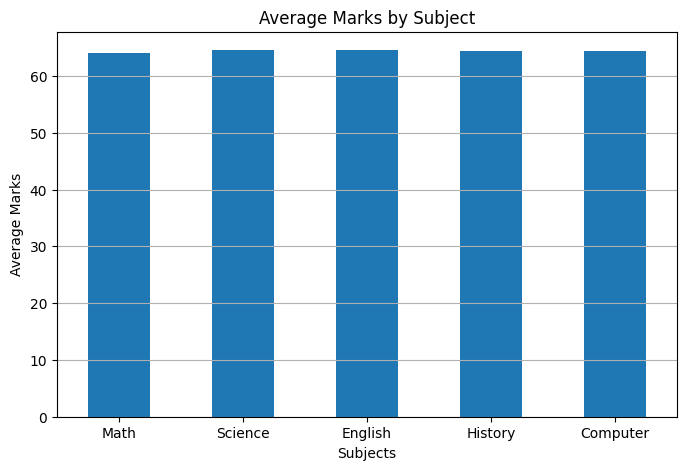

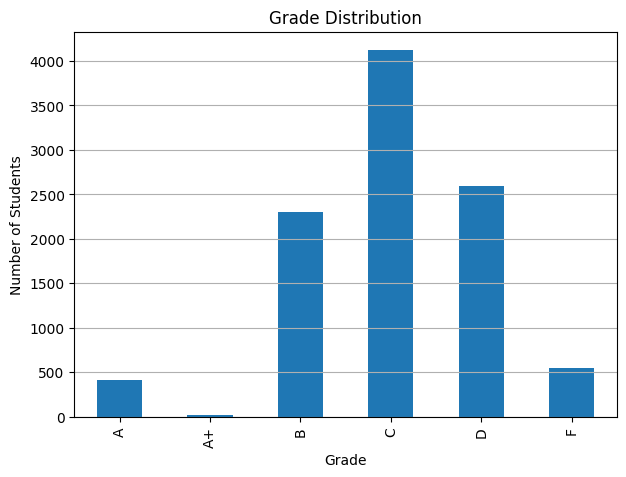

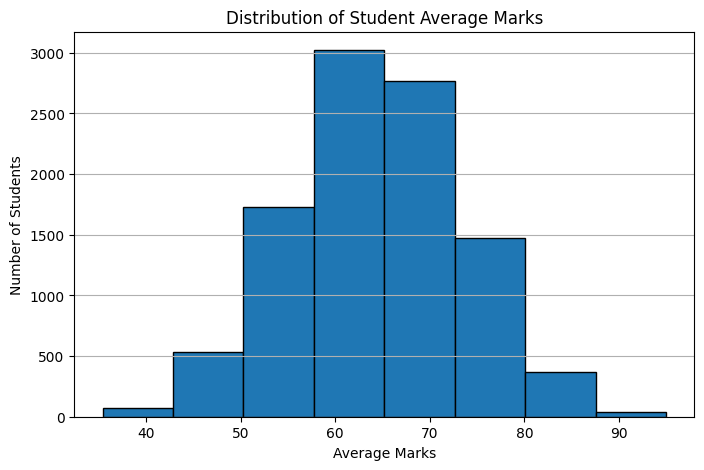

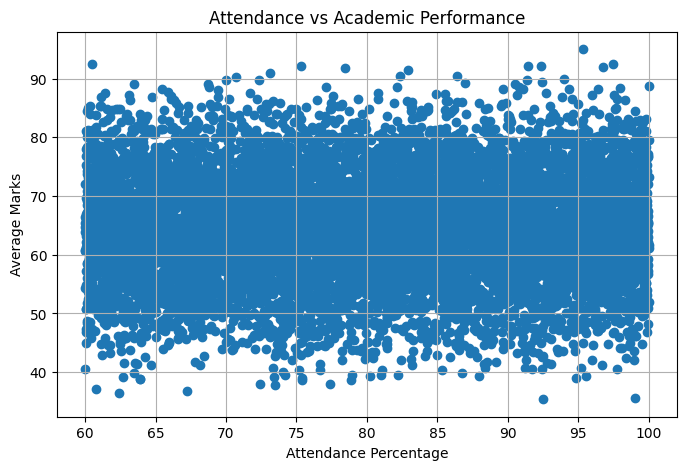


PROJECT INSIGHTS
-------------------------
Best Performing Subject: Science
Subject Needing Improvement: Math
Number of Students Needing Support: 546
Overall Pass Percentage: 99.75 %


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Copy cleaned dataset
analysis_df = clean_df.copy()

# Subject columns
subjects = ["Math", "Science", "English", "History", "Computer"]

# Calculate total and average marks
analysis_df["TotalMarks"] = analysis_df[subjects].sum(axis=1)
analysis_df["Average"] = analysis_df[subjects].mean(axis=1)

# Assign grades
def calculate_grade(avg):
    if avg >= 90:
        return "A+"
    elif avg >= 80:
        return "A"
    elif avg >= 70:
        return "B"
    elif avg >= 60:
        return "C"
    elif avg >= 50:
        return "D"
    else:
        return "F"

analysis_df["Grade"] = analysis_df["Average"].apply(calculate_grade)

# Assign result
analysis_df["Result"] = np.where(
    analysis_df["Average"] >= 40,
    "Pass",
    "Fail"
)

# Display analyzed data
display(
    analysis_df[
        ["StudentID", "Name", "TotalMarks", "Average", "Grade", "Result"]
    ].head(10)
)

# -------------------------------
# 1. Key Performance Statistics
# -------------------------------

print("Total Students:", len(analysis_df))
print("Overall Average:", round(analysis_df["Average"].mean(), 2))
print("Highest Average:", round(analysis_df["Average"].max(), 2))
print("Lowest Average:", round(analysis_df["Average"].min(), 2))

pass_rate = (analysis_df["Result"] == "Pass").mean() * 100
print("Pass Percentage:", round(pass_rate, 2), "%")

# -------------------------------
# 2. Subject-wise Average
# -------------------------------

subject_averages = analysis_df[subjects].mean()

print("\nSubject-wise Average Marks:")
print(subject_averages.round(2))

# -------------------------------
# 3. Top 5 Students
# -------------------------------

top_students = analysis_df.sort_values(
    by="Average",
    ascending=False
).head(5)

print("\nTop 5 Students:")
display(
    top_students[
        ["StudentID", "Name", "Average", "Grade"]
    ]
)

# -------------------------------
# 4. Students Needing Support
# -------------------------------

support_students = analysis_df[
    analysis_df["Average"] < 50
]

print("\nStudents Needing Academic Support:")
display(
    support_students[
        ["StudentID", "Name", "Average", "Grade"]
    ]
)

# -------------------------------
# 5. Visualization Dashboard
# -------------------------------

plt.figure(figsize=(8, 5))
subject_averages.plot(
    kind="bar",
    title="Average Marks by Subject"
)
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Grade distribution
plt.figure(figsize=(7, 5))
analysis_df["Grade"].value_counts().sort_index().plot(
    kind="bar",
    title="Grade Distribution"
)
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.grid(axis="y")
plt.show()

# Average marks distribution
plt.figure(figsize=(8, 5))
plt.hist(
    analysis_df["Average"],
    bins=8,
    edgecolor="black"
)
plt.title("Distribution of Student Average Marks")
plt.xlabel("Average Marks")
plt.ylabel("Number of Students")
plt.grid(axis="y")
plt.show()

# Attendance versus average marks
plt.figure(figsize=(8, 5))
plt.scatter(
    analysis_df["AttendancePercent"],
    analysis_df["Average"]
)
plt.title("Attendance vs Academic Performance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Average Marks")
plt.grid(True)
plt.show()

# -------------------------------
# 6. Automatic Project Insights
# -------------------------------

best_subject = subject_averages.idxmax()
weakest_subject = subject_averages.idxmin()

print("\nPROJECT INSIGHTS")
print("-------------------------")
print("Best Performing Subject:", best_subject)
print("Subject Needing Improvement:", weakest_subject)
print("Number of Students Needing Support:", len(support_students))
print("Overall Pass Percentage:", round(pass_rate, 2), "%")

In [19]:
# ==========================================
# MODULE 9: REPORT GENERATION
# ==========================================

clean_df.to_csv(
    "cleaned_student_records.csv",
    index=False
)

subject_summary.to_csv(
    "subject_performance_summary.csv"
)

attendance_summary.to_csv(
    "attendance_analysis_summary.csv"
)

top_students.to_csv(
    "top_10_students.csv",
    index=False
)

support_students.to_csv(
    "students_needing_support.csv",
    index=False
)

print("All CSV reports generated successfully!")
from google.colab import files

files.download("cleaned_student_records.csv")

All CSV reports generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
print("FINAL PROJECT INSIGHTS")
print("=" * 50)

print("Total students analyzed:", len(clean_df))
print("Strongest subject:", strongest_subject)
print("Weakest subject:", weakest_subject)
print("Overall average marks:", round(clean_df["Average"].mean(), 2))
print("Attendance-mark correlation:", round(correlation, 3))

print("\nGrade Distribution:")
print(grade_distribution)

print("\nAttendance Summary:")
print(attendance_summary)

FINAL PROJECT INSIGHTS
Total students analyzed: 10000
Strongest subject: Science
Weakest subject: Math
Overall average marks: 64.38
Attendance-mark correlation: -0.002

Grade Distribution:
CalculatedGrade
A      417
A+      14
B     2307
C     4125
D     2591
F      546
Name: count, dtype: int64

Attendance Summary:
                    StudentCount  AverageMarks  AverageAttendance
AttendanceCategory                                               
Low                            0           NaN                NaN
Moderate                    3803         64.40              67.40
Good                        3747         64.40              82.60
Excellent                   2450         64.33              95.07


In [21]:
# Export final analyzed dataset
analysis_df.to_csv(
    "final_student_analysis.csv",
    index=False
)

# Export subject-wise averages
subject_averages.to_csv(
    "subject_average_report.csv"
)

# Export top-performing students
top_students.to_csv(
    "top_students_report.csv",
    index=False
)

# Export students needing support
support_students.to_csv(
    "students_needing_support.csv",
    index=False
)

print("All reports exported successfully!")

All reports exported successfully!


In [22]:
print("=" * 50)
print("STUDENT PERFORMANCE DATA ANALYSIS SYSTEM")
print("=" * 50)

print("Total Students Analyzed:", len(analysis_df))
print("Overall Average:", round(analysis_df["Average"].mean(), 2))
print("Pass Percentage:", round(pass_rate, 2), "%")
print("Best Subject:", best_subject)
print("Weakest Subject:", weakest_subject)
print("Top Student:", top_students.iloc[0]["Name"])
print("Students Needing Support:", len(support_students))

print("\nProject analysis completed successfully!")

STUDENT PERFORMANCE DATA ANALYSIS SYSTEM
Total Students Analyzed: 10000
Overall Average: 64.38
Pass Percentage: 99.75 %
Best Subject: Science
Weakest Subject: Math
Top Student: Benjamin Diaz
Students Needing Support: 546

Project analysis completed successfully!
